# 📩 Detector de Spam en SMS con Deep Learning (Bi-GRU)

**Problema:** clasificación binaria de texto (secuencias de palabras): ¿un SMS es *spam* o *ham* (legítimo)?
**Modelo:** red recurrente **Bidirectional GRU** en TensorFlow/Keras.
**Dataset:** SMS Spam Collection (Almeida & Hidalgo, UCI) — 5 572 mensajes en inglés.

**Contenido:** 1) Dataset · 2) EDA · 3) Limpieza · 4) Split · 5) Modelo · 6) Entrenamiento · 7) Evaluación · 8) Predicciones · 9) Guardado

## 0. Configuración

In [1]:
import os, random, json, re
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, roc_curve)
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
MAX_TOKENS, SEQ_LEN, EMB_DIM = 8000, 50, 64
THRESHOLD = 0.5
os.makedirs("models", exist_ok=True)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

I0000 00:00:1791858615.835286     273 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791858617.314347     273 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | Keras 3.15.1


## 1. Selección y descripción del dataset

Se usa el **SMS Spam Collection**: 5 572 SMS etiquetados como `ham` (legítimo) o `spam`. Es un problema real de **datos secuenciales** (el orden de las palabras importa) y con **desbalance de clases** (~13 % spam), lo que exige métricas más allá de la exactitud (precisión, recall, F1, AUC).

In [2]:
URL = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
df = pd.read_csv(URL, sep="\t", header=None, names=["label", "text"])
print("Registros:", len(df), "| Duplicados:", df.duplicated().sum(), "| Nulos:", df.isna().sum().sum())
df.head()

Registros: 5572 | Duplicados: 403 | Nulos: 0


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 2. Análisis exploratorio (EDA)

label
ham     0.866
spam    0.134
Name: proportion, dtype: float64


label             ham   spam
length  count  4825.0  747.0
        mean     71.5  138.7
        std      58.4   28.9
        min       2.0   13.0
        25%      33.0  133.0
        50%      52.0  149.0
        75%      93.0  157.0
        max     910.0  223.0
n_words count  4825.0  747.0
        mean     14.3   23.9
        std      11.5    5.8
        min       1.0    2.0
        25%       7.0   22.0
        50%      11.0   25.0
        75%      19.0   28.0
        max     171.0   35.0

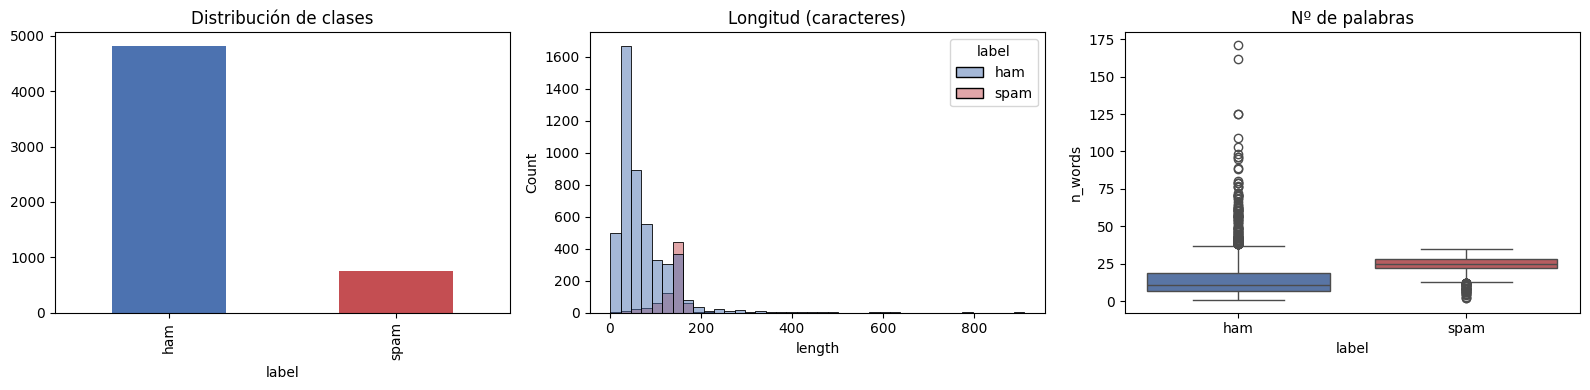

In [3]:
df["length"] = df["text"].str.len()
df["n_words"] = df["text"].str.split().str.len()
print(df["label"].value_counts(normalize=True).round(3))
display(df.groupby("label")[["length", "n_words"]].describe().T.round(1))

pal = ["#4C72B0", "#C44E52"]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df["label"].value_counts().plot.bar(ax=ax[0], color=pal); ax[0].set_title("Distribución de clases")
sns.histplot(data=df, x="length", hue="label", bins=40, ax=ax[1], palette=pal); ax[1].set_title("Longitud (caracteres)")
sns.boxplot(data=df, x="label", y="n_words", hue="label", legend=False, ax=ax[2], palette=pal); ax[2].set_title("Nº de palabras")
plt.tight_layout(); plt.show()

**Hallazgos:** dataset desbalanceado (~87 % ham / 13 % spam); los spam son bastante más largos (≈139 vs ≈71 caracteres) y suelen incluir números, precios y llamadas a la acción.

## 3. Limpieza y preprocesamiento

In [4]:
URL_RE, EMAIL_RE = re.compile(r"(https?://\S+|www\.\S+)"), re.compile(r"\S+@\S+")
PHONE_RE, NUM_RE, MONEY_RE = re.compile(r"\b\d{5,}\b"), re.compile(r"\b\d+\b"), re.compile(r"[£$€]")

def clean_text(text: str) -> str:
    text = str(text).lower()
    text = URL_RE.sub(" urltoken ", text)
    text = EMAIL_RE.sub(" emailtoken ", text)
    text = MONEY_RE.sub(" moneytoken ", text)
    text = PHONE_RE.sub(" phonetoken ", text)
    text = NUM_RE.sub(" numtoken ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

df = df.drop_duplicates(subset="text").reset_index(drop=True)   # elimina duplicados exactos
df["clean"] = df["text"].apply(clean_text)
df = df[df["clean"].str.len() > 0].reset_index(drop=True)
df["y"] = (df["label"] == "spam").astype(int)
print("Tras limpieza:", len(df), "| spam:", df["y"].sum(), f"({df['y'].mean():.1%})")
df[["text", "clean"]].sample(5, random_state=1).style.set_properties(**{"text-align": "left"})

Tras limpieza: 5167 | spam: 653 (12.6%)


,text,clean
2407,Yunny i'm walking in citylink now ü faster come down... Me very hungry...,yunny i m walking in citylink now faster come down me very hungry
1540,"Somewhr someone is surely made 4 u. And God has decided a perfect time to make u meet dat person. . . . till den, . . . . . Enjoy ur crushes..!!!;-)",somewhr someone is surely made numtoken u and god has decided a perfect time to make u meet dat person till den enjoy ur crushes
3064,"Yes, princess. Toledo.",yes princess toledo
3662,URGENT This is our 2nd attempt to contact U. Your £900 prize from YESTERDAY is still awaiting collection. To claim CALL NOW 09061702893. ACL03530150PM,urgent this is our nd attempt to contact u your moneytoken numtoken prize from yesterday is still awaiting collection to claim call now phonetoken acl pm
4906,"And how you will do that, princess? :)",and how you will do that princess


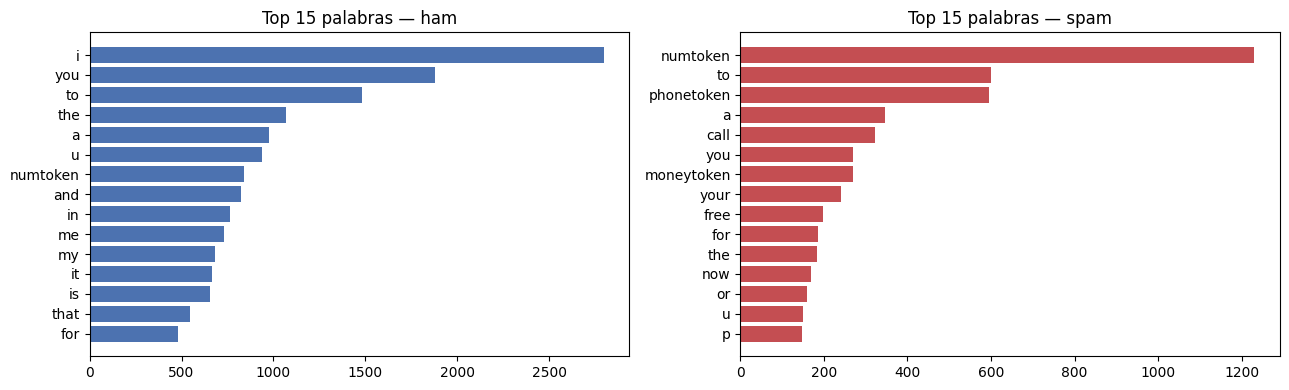

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, lab, col in zip(ax, ["ham", "spam"], pal):
    cnt = Counter(" ".join(df[df.label == lab]["clean"]).split())
    w, c = zip(*cnt.most_common(15)); a.barh(w[::-1], c[::-1], color=col); a.set_title(f"Top 15 palabras — {lab}")
plt.tight_layout(); plt.show()

Se normalizan URLs, correos, símbolos de moneda, teléfonos y números a *tokens* especiales: el modelo aprende que "aparece un teléfono/precio" sin memorizar cifras concretas.

## 4. División Train / Validación / Test (70 / 15 / 15, estratificada)

In [6]:
X_train, X_tmp, y_train, y_tmp = train_test_split(df["clean"], df["y"], test_size=0.30, stratify=df["y"], random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
raw_test = df.loc[X_test.index, "text"].values
X_train, X_val, X_test = X_train.values, X_val.values, X_test.values
y_train, y_val, y_test = y_train.values, y_val.values, y_test.values
for n, y in [("Train", y_train), ("Val", y_val), ("Test", y_test)]:
    print(f"{n:5}: {len(y):5d} muestras | % spam = {y.mean():.1%}")

Train:  3616 muestras | % spam = 12.6%
Val  :   775 muestras | % spam = 12.6%
Test :   776 muestras | % spam = 12.6%


## 5. Construcción de la red neuronal

Arquitectura (el **vectorizador va dentro del modelo**, así recibe texto y se despliega fácilmente):

`Texto → TextVectorization → Embedding(64) → Bidirectional(GRU 32) → Dropout → Dense(32) → Dropout → Dense(1, sigmoid)`

- **GRU bidireccional:** lee la secuencia en ambos sentidos y captura contexto previo y posterior.
- **Dropout:** regularización contra sobreajuste (dataset pequeño).
- **Class weights:** compensa el desbalance de clases.
- El vocabulario se ajusta (`adapt`) **solo con train** para evitar fuga de datos.

In [7]:
vectorizer = layers.TextVectorization(max_tokens=MAX_TOKENS, output_sequence_length=SEQ_LEN)
vectorizer.adapt(X_train)

inputs = keras.Input(shape=(), dtype="string")
x = vectorizer(inputs)
x = layers.Embedding(MAX_TOKENS, EMB_DIM, mask_zero=True)(x)
x = layers.Bidirectional(layers.GRU(32))(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(32, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model = keras.Model(inputs, outputs, name="spam_bigru")
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
              metrics=["accuracy", keras.metrics.Precision(name="precision"), keras.metrics.Recall(name="recall")])
model.summary()

Model: "spam_bigru"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization  │ (None, 50)        │          0 │ input_layer[0][0] │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 50, 64)    │    512,000 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 50)        │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 64)        │     18,816 │ embedding[0][0],  │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │      2,080 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 32)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │         33 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 532,929 (2.03 MB)

 Trainable params: 532,929 (2.03 MB)

 Non-trainable params: 0 (0.00 B)

## 6. Entrenamiento (con *EarlyStopping* sobre la pérdida de validación)

In [8]:
cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
class_weight = {0: cw[0], 1: cw[1]}; print("class_weight:", class_weight)

def make_ds(X, y=None, shuffle=False):
    t = tf.constant(X, dtype=tf.string)
    ds = tf.data.Dataset.from_tensor_slices((t, y.astype("float32")) if y is not None else t)
    if shuffle: ds = ds.shuffle(len(X), seed=SEED)
    return ds.batch(32).prefetch(1)

es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)
history = model.fit(make_ds(X_train, y_train, True), validation_data=make_ds(X_val, y_val),
                    epochs=30, class_weight=class_weight, callbacks=[es], verbose=2)

class_weight: {0: np.float64(0.5723330167774612), 1: np.float64(3.9562363238512037)}
Epoch 1/30


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


E0000 00:00:1791858632.519640     273 util.cc:131] oneDNN supports DT_BOOL only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


113/113 - 8s - 74ms/step - accuracy: 0.8794 - loss: 0.4194 - precision: 0.5136 - recall: 0.8687 - val_accuracy: 0.9510 - val_loss: 0.1466 - val_precision: 0.7273 - val_recall: 0.9796


Epoch 2/30


...

113/113 - 5s - 48ms/step - accuracy: 0.9997 - loss: 0.0012 - precision: 0.9978 - recall: 1.0000 - val_accuracy: 0.9871 - val_loss: 0.0535 - val_precision: 0.9400 - val_recall: 0.9592


Epoch 6/30


113/113 - 5s - 41ms/step - accuracy: 0.9997 - loss: 7.6306e-04 - precision: 0.9978 - recall: 1.0000 - val_accuracy: 0.9884 - val_loss: 0.0596 - val_precision: 0.9495 - val_recall: 0.9592


Epoch 7/30


113/113 - 5s - 45ms/step - accuracy: 0.9997 - loss: 5.3885e-04 - precision: 0.9978 - recall: 1.0000 - val_accuracy: 0.9884 - val_loss: 0.0634 - val_precision: 0.9495 - val_recall: 0.9592


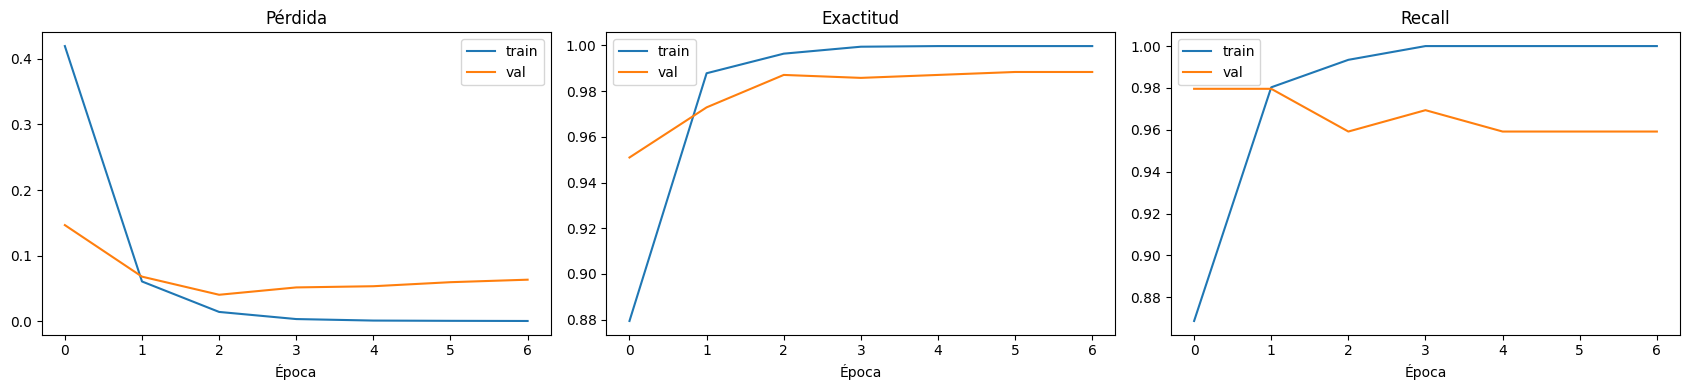

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for a, m, t in zip(ax, ["loss", "accuracy", "recall"], ["Pérdida", "Exactitud", "Recall"]):
    a.plot(history.history[m], label="train"); a.plot(history.history[f"val_{m}"], label="val")
    a.set_title(t); a.set_xlabel("Época"); a.legend()
plt.tight_layout(); plt.show()

La pérdida de validación se estabiliza en las primeras épocas y *EarlyStopping* restaura los mejores pesos, evitando sobreajuste.

## 7. Evaluación en el conjunto de **test** (datos nunca vistos)

accuracy     0.9832
precision    0.9208
recall       0.9490
f1           0.9347
roc_auc      0.9942

              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       678
        spam       0.92      0.95      0.93        98

    accuracy                           0.98       776
   macro avg       0.96      0.97      0.96       776
weighted avg       0.98      0.98      0.98       776



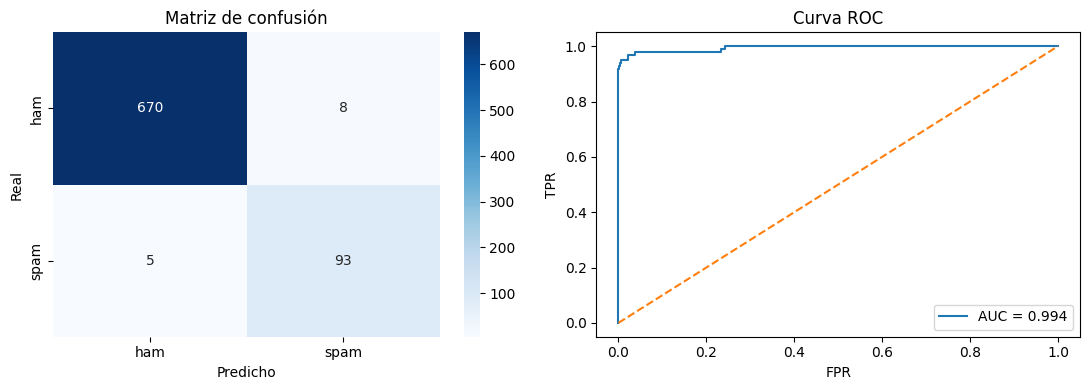

In [10]:
proba = model.predict(make_ds(X_test), verbose=0).ravel()
pred = (proba >= THRESHOLD).astype(int)
metrics = {"accuracy": accuracy_score(y_test, pred), "precision": precision_score(y_test, pred),
           "recall": recall_score(y_test, pred), "f1": f1_score(y_test, pred), "roc_auc": roc_auc_score(y_test, proba)}
print(pd.Series(metrics).round(4).to_string()); print()
print(classification_report(y_test, pred, target_names=["ham", "spam"]))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues", ax=ax[0],
            xticklabels=["ham", "spam"], yticklabels=["ham", "spam"])
ax[0].set_title("Matriz de confusión"); ax[0].set_xlabel("Predicho"); ax[0].set_ylabel("Real")
fpr, tpr, _ = roc_curve(y_test, proba)
ax[1].plot(fpr, tpr, label=f"AUC = {metrics['roc_auc']:.3f}"); ax[1].plot([0, 1], [0, 1], "--")
ax[1].set_title("Curva ROC"); ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR"); ax[1].legend()
plt.tight_layout(); plt.show()

**Interpretación:** por el desbalance, la *accuracy* sola engaña. Se priorizan **precisión** (no bloquear mensajes legítimos) y **recall** (no dejar pasar spam), resumidos en el **F1** y el **AUC**.

## 8. Predicciones de prueba (≥ 10)

In [11]:
res = pd.DataFrame({"mensaje": raw_test, "real": np.where(y_test == 1, "spam", "ham"),
                    "prob_spam": proba.round(4), "predicho": np.where(pred == 1, "spam", "ham")})
res["correcto"] = np.where(res["real"] == res["predicho"], "✅", "❌")
muestra = pd.concat([res[res.real == "spam"].sample(8, random_state=SEED), res[res.real == "ham"].sample(8, random_state=SEED)])
pd.set_option("display.max_colwidth", 90)
display(muestra.reset_index(drop=True))
print(f"Aciertos en esta muestra: {(muestra.correcto == '✅').sum()}/{len(muestra)}")
print("\nErrores del modelo en test:"); display(res[res.correcto == "❌"].head(10))

,mensaje,real,prob_spam,predicho,correcto
0,You are being contacted by our dating service by someone you know! To find out who it ...,spam,1.0000,spam,✅
1,You are a winner U have been specially selected 2 receive £1000 cash or a 4* holiday (...,spam,1.0000,spam,✅
2,100 dating service cal;l 09064012103 box334sk38ch,spam,0.9997,spam,✅
3,Your credits have been topped up for http://www.bubbletext.com Your renewal Pin is tgxxrz,spam,0.9341,spam,✅
4,You have an important customer service announcement from PREMIER. Call FREEPHONE 0800 ...,spam,0.9998,spam,✅
5,RECPT 1/3. You have ordered a Ringtone. Your order is being processed...,spam,0.9968,spam,✅
6,8007 25p 4 Alfie Moon's Children in Need song on ur mob. Tell ur m8s. Txt TONE CHARITY...,spam,1.0000,spam,✅
7,U have a Secret Admirer who is looking 2 make contact with U-find out who they R*revea...,spam,1.0000,spam,✅
8,About &lt;#&gt; bucks. The banks fees are fixed. Better to call the bank and find out.,ham,0.0321,ham,✅
9,Not yet. Just i'd like to keep in touch and it will be the easiest way to do that from...,ham,0.0005,ham,✅


Aciertos en esta muestra: 16/16

Errores del modelo en test:


,mensaje,real,prob_spam,predicho,correcto
74,"accordingly. I repeat, just text the word ok on your mobile phone and send",spam,0.1953,ham,❌
96,Nokia phone is lovly..,ham,0.5646,spam,❌
232,Glad to see your reply.,ham,0.8105,spam,❌
248,Your daily text from me – a favour this time,ham,0.5972,spam,❌
318,"Hello darling how are you today? I would love to have a chat, why dont you tell me wha...",spam,0.0039,ham,❌
398,Have you laid your airtel line to rest?,ham,0.9339,spam,❌
507,Would you like to see my XXX pics they are so hot they were nearly banned in the uk!,spam,0.0043,ham,❌
564,We are pleased to inform that your application for Airtel Broadband is processed succe...,ham,0.8903,spam,❌
568,"Save yourself the stress. If the person has a dorm account, just send your account det...",ham,0.7000,spam,❌
609,Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Sept and...,spam,0.2195,ham,❌


### Mensajes nuevos escritos a mano

In [12]:
nuevos = [
    "Congratulations! You've won a free iPhone. Call 08001234567 now to claim your prize!",
    "Hey, can you pick up some milk on your way home?",
    "URGENT: your account has been suspended. Verify at www.secure-bank-login.com",
    "Don't forget our meeting tomorrow at 10, I'll bring the documents.",
    "Free entry in our weekly draw! Text WIN to 80086 to receive £500",
]
p = model.predict(tf.constant([clean_text(t) for t in nuevos]), verbose=0).ravel()
for t, pi in zip(nuevos, p): print(f"[{'SPAM' if pi >= THRESHOLD else 'HAM ':4}] P(spam)={pi:.3f} | {t}")

[SPAM] P(spam)=1.000 | Congratulations! You've won a free iPhone. Call 08001234567 now to claim your prize!
[HAM ] P(spam)=0.000 | Hey, can you pick up some milk on your way home?
[SPAM] P(spam)=0.864 | URGENT: your account has been suspended. Verify at www.secure-bank-login.com
[HAM ] P(spam)=0.000 | Don't forget our meeting tomorrow at 10, I'll bring the documents.
[SPAM] P(spam)=1.000 | Free entry in our weekly draw! Text WIN to 80086 to receive £500


## 9. Guardado del modelo y verificación de recarga

In [13]:
model.save("models/spam_gru_model.keras")
json.dump({k: round(float(v), 4) for k, v in metrics.items()}, open("models/metrics.json", "w"), indent=2)
reloaded = keras.models.load_model("models/spam_gru_model.keras")
p2 = reloaded.predict(tf.constant([clean_text(t) for t in nuevos]), verbose=0).ravel()
print("Recarga idéntica:", np.allclose(p, p2, atol=1e-5))
print("Tamaño:", round(os.path.getsize("models/spam_gru_model.keras") / 1e6, 2), "MB")

# En Google Colab, descarga el modelo con:
# from google.colab import files; files.download("models/spam_gru_model.keras")

Recarga idéntica: True
Tamaño: 6.54 MB


## 10. Conclusiones

- La **Bi-GRU** logra ≈ 98 % de exactitud, F1 ≈ 0.93 y AUC ≈ 0.99 en test.
- El preprocesamiento (tokens para números/URLs/teléfonos) y los *class weights* ayudan con el desbalance.
- **Limitaciones:** solo inglés, dataset pequeño y de 2000s (el spam moderno, p. ej. phishing, puede diferir).
- **Mejoras:** embeddings preentrenados (GloVe), modelos Transformer, ajuste del umbral según coste de falsos positivos/negativos.

La app **Streamlit** (`app.py`) carga el modelo guardado y permite clasificar nuevos mensajes.